<a href="https://colab.research.google.com/github/AdrianRMCA/Metodos-numericos-1/blob/main/Metodo%20de%20Neville.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


## Método de Neville

El **método de Neville** permite evaluar de forma recursiva el polinomio de interpolación de Lagrange en un punto dado $x$, reutilizando cálculos previos de menor grado para evitar repetir trabajo y facilitar el control de la precisión.

Si $Q_{i,j}(x)$ denota el polinomio de interpolación de grado $j$ que concuerda con $f$ en los $j+1$ puntos consecutivos $x_{i-j}, x_{i-j+1}, \ldots, x_{i-1}, x_i$ (con $0 \leq j \leq i$), la relación recursiva para $j \geq 1$ es:

$$
Q_{i,j}(x) = \frac{(x-x_{i-j})Q_{i,j-1}(x)-(x-x_i)Q_{i-1,j-1}(x)}{x_i-x_{i-j}}
$$

En el **Ejemplo 2** se busca aproximar $f(1.5)$ a partir de los datos de la función de Bessel de primera clase de orden cero, $J_0(x)$, partiendo de los nodos $x_0=1.0$, $x_1=1.3$, $x_2=1.6$, $x_3=1.9$, $x_4=2.2$ y agregando posteriormente el nodo adicional $x_5=2.5$ con $f(2.5)=-0.0483838$.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
import scipy
from scipy.special import jv

In [2]:
def neville_tabla(x_nodos,y_nodos,x_eval):
    n=len(x_nodos)
    Q=np.zeros((n,n),dtype=float)
    Q[:,0]=y_nodos
    for i in range(1,n):
        for j in range(1,i+1):
            Q[i,j]=((x_eval-x_nodos[i-j])*Q[i,j-1]-(x_eval-x_nodos[i])*Q[i-1,j-1])/(x_nodos[i]-x_nodos[i-j])
    return Q

In [3]:
x_eval=1.5

x_base=np.array([1.0,1.3,1.6,1.9,2.2],dtype=float)
y_base=np.array([0.7651977,0.6200860,0.4554022,0.2818186,0.1103623],dtype=float)

Q_base=neville_tabla(x_base,y_base,x_eval)
print("Tabla de Neville (n=4, hasta x4=2.2):")
print(np.round(Q_base,7))
print(f"\nAproximacion Q_{{4,4}}({x_eval}) = {Q_base[4,4]:.7f}")

x_ext=np.append(x_base,2.5)
y_ext=np.append(y_base,-0.0483838)

Q_ext=neville_tabla(x_ext,y_ext,x_eval)
print("\nTabla de Neville extendida (hasta x5=2.5):")
print(np.round(Q_ext,7))
print(f"\nAproximacion Q_{{5,5}}({x_eval}) = {Q_ext[5,5]:.7f}")
print(f"Valor Bessel J0({x_eval}) (scipy)   = {jv(0,x_eval):.7f}")

Tabla de Neville (n=4, hasta x4=2.2):
[[0.7651977 0.        0.        0.        0.       ]
 [0.620086  0.5233449 0.        0.        0.       ]
 [0.4554022 0.5102968 0.5124715 0.        0.       ]
 [0.2818186 0.5132634 0.5112857 0.5118127 0.       ]
 [0.1103623 0.510427  0.5137361 0.5118302 0.51182  ]]

Aproximacion Q_{4,4}(1.5) = 0.5118200

Tabla de Neville extendida (hasta x5=2.5):
[[ 0.7651977  0.         0.         0.         0.         0.       ]
 [ 0.620086   0.5233449  0.         0.         0.         0.       ]
 [ 0.4554022  0.5102968  0.5124715  0.         0.         0.       ]
 [ 0.2818186  0.5132634  0.5112857  0.5118127  0.         0.       ]
 [ 0.1103623  0.510427   0.5137361  0.5118302  0.51182    0.       ]
 [-0.0483838  0.4807699  0.5301984  0.511907   0.511843   0.5118277]]

Aproximacion Q_{5,5}(1.5) = 0.5118277
Valor Bessel J0(1.5) (scipy)   = 0.5118277


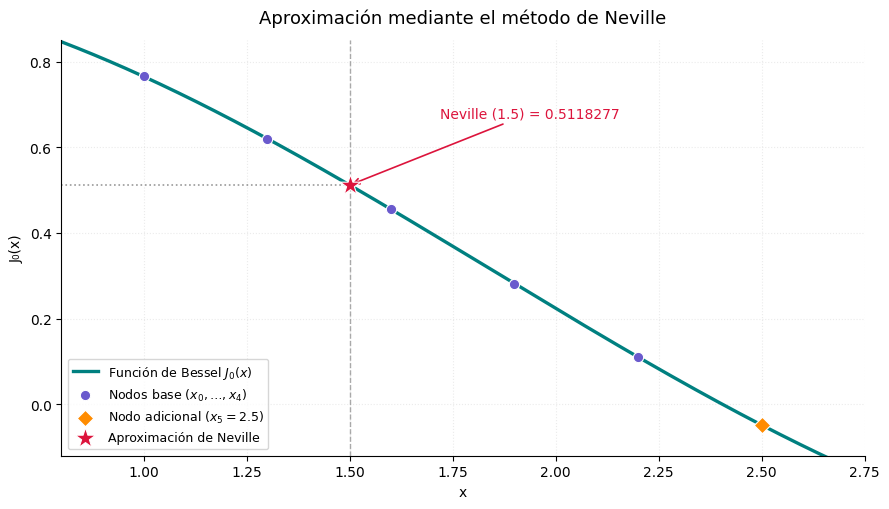

In [4]:
xx = np.linspace(0.8, 2.75, 400)
yy_bessel = jv(0, xx)

fig, ax = plt.subplots(figsize=(9, 5.2))
ax.plot(xx, yy_bessel, color='teal', linewidth=2.4,
        label=r'Función de Bessel $J_0(x)$')
ax.scatter(x_base, y_base, color='slateblue', s=55, edgecolor='white',
           linewidth=0.8, zorder=4, label=r'Nodos base ($x_0,\ldots,x_4$)')
ax.scatter([x_ext[-1]], [y_ext[-1]], color='darkorange', marker='D', s=70,
           edgecolor='white', linewidth=0.8, zorder=5, label=r'Nodo adicional ($x_5=2.5$)')
ax.scatter([x_eval], [Q_ext[-1, -1]], color='crimson', marker='*', s=240,
           edgecolor='white', linewidth=0.8, zorder=6, label='Aproximación de Neville')

# Guías discretas para ubicar el valor interpolado
ax.axvline(x_eval, color='gray', linestyle='--', linewidth=1, alpha=0.65)
ax.hlines(Q_ext[-1, -1], xmin=0.8, xmax=x_eval,
          color='gray', linestyle=':', linewidth=1.2, alpha=0.8)
ax.annotate(f'Neville (1.5) = {Q_ext[-1, -1]:.7f}',
            xy=(x_eval, Q_ext[-1, -1]), xytext=(1.72, 0.67),
            arrowprops=dict(arrowstyle='->', color='crimson', lw=1.2),
            fontsize=10, color='crimson')

ax.set_xlim(0.8, 2.75)
ax.set_ylim(-0.12, 0.85)
ax.set_title('Aproximación mediante el método de Neville', fontsize=13, pad=12)
ax.set_xlabel('x')
ax.set_ylabel('J₀(x)')
ax.grid(True, linestyle=':', alpha=0.25)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(loc='lower left', frameon=True, fontsize=9)
fig.tight_layout()
plt.show()
